Partie A — Chargement et Exploration des Données


   Unnamed: 0        asin   helpful  overall  \
0           0  0528881469    [0, 0]      5.0   
1           1  0528881469  [12, 15]      1.0   
2           2  0528881469  [43, 45]      3.0   
3           3  0528881469   [9, 10]      2.0   
4           4  0528881469    [0, 0]      1.0   

                                          reviewText   reviewTime  \
0  We got this GPS for my husband who is an (OTR)...   06 2, 2013   
1  I'm a professional OTR truck driver, and I bou...  11 25, 2010   
2  Well, what can I say.  I've had this unit in m...   09 9, 2010   
3  Not going to write a long review, even thought...  11 24, 2010   
4  I've had mine for a year and here's what we go...  09 29, 2011   

       reviewerID              reviewerName  \
0   AO94DHGC771SJ                   amazdnu   
1   AMO214LNFCEI4           Amazon Customer   
2  A3N7T0DY83Y4IG             C. A. Freeman   
3  A1H8PY3QHMQQA0  Dave M. Shaw "mack dave"   
4  A24EV6RXELQZ63               Wayne Smith   

             

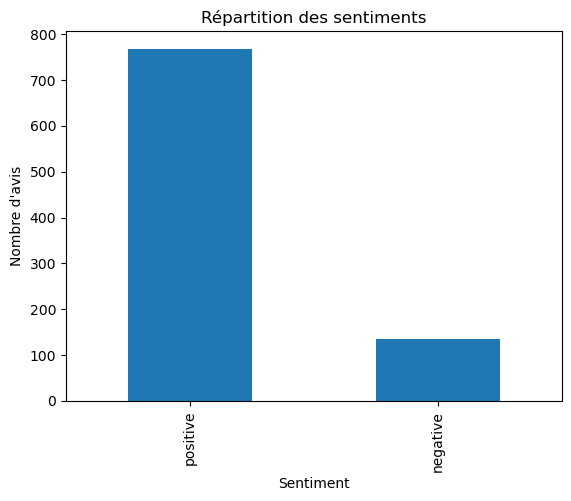


Longueur moyenne des avis :
761.5924695459579

Statistiques des longueurs :
count      903.000000
mean       761.592470
std       1188.531287
min         31.000000
25%        161.500000
50%        328.000000
75%        813.500000
max      11622.000000
Name: length, dtype: float64


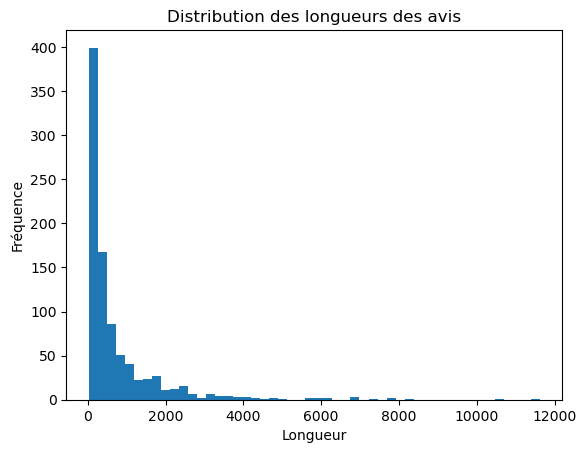

In [5]:
#1. Importer les bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Afficher toutes les colonnes
pd.set_option('display.max_columns', None)

#2. Charger le dataset
df = pd.read_csv("amazon_reviews.csv")

#3. Afficher les premières observations
print(df.head())

#4. Identifier les colonnes disponibles
print("\nColonnes du dataset :")
print(df.columns)

#5. Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(df.isnull().sum())

# Supprimer les lignes où reviewText est vide
df = df.dropna(subset=['reviewText'])

#6. Donner la taille totale du dataset
print("\nNombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

# Supprimer les avis neutres (note = 3)
df = df[df['overall'] != 3]

#7. Créer la colonne sentiment
df['sentiment'] = df['overall'].apply(
    lambda x: 'positive' if x > 3 else 'negative'
)

# Étudier la répartition des classes
print("\nRépartition des sentiments :")
print(df['sentiment'].value_counts())

# Graphique des sentiments
df['sentiment'].value_counts().plot(kind='bar')

plt.title("Répartition des sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Nombre d'avis")

plt.show()

#8. Calculer la longueur des avis
df['length'] = df['reviewText'].astype(str).apply(len)

print("\nLongueur moyenne des avis :")
print(df['length'].mean())

#9. Afficher quelques statistiques
print("\nStatistiques des longueurs :")
print(df['length'].describe())

#10. Histogramme des longueurs
plt.hist(df['length'], bins=50)

plt.title("Distribution des longueurs des avis")
plt.xlabel("Longueur")
plt.ylabel("Fréquence")

plt.show()

1. Le dataset est-il équilibré entre avis positifs et négatifs ?

Non, le dataset n’est pas équilibré.

D’après le graphique obtenu :

les avis positifs sont largement majoritaires,
les avis négatifs sont beaucoup moins nombreux.

On observe environ :

plus de 700 avis positifs,
environ 150 avis négatifs.

Le dataset est donc déséquilibré en faveur des avis positifs.

2. Pourquoi l’équilibrage des classes est important ?

L’équilibrage des classes est important afin d’éviter qu’un modèle d’apprentissage automatique soit biaisé vers la classe majoritaire.

Dans ce projet :

si les avis positifs sont beaucoup plus nombreux,
le modèle risque de prédire “positif” presque tout le temps.

Cela peut donner une bonne accuracy, mais de mauvaises performances pour détecter les avis négatifs.

Un dataset équilibré permet :

un apprentissage plus juste,
une meilleure généralisation,
des prédictions plus fiables.

3. La longueur d’un avis peut-elle influencer le sentiment ?

Oui, la longueur d’un avis peut influencer le sentiment.

D’après les statistiques :

la longueur moyenne des avis est d’environ 761 caractères,
certains avis sont très longs et contiennent beaucoup de détails.

Les avis longs expriment souvent :

plus d’émotions,
plus d’explications,
plus d’informations utiles pour identifier le sentiment.

À l’inverse, les avis très courts peuvent être plus difficiles à analyser car ils contiennent peu de contexte.

Ainsi, la longueur des avis peut avoir un impact sur la qualité de la classification des sentiments.

Partie B — Prétraitement des Textes

In [10]:
#1. Importer les bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import re
import string

#2. Télécharger les ressources NLTK
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

#3. Importer les outils NLP
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

#4. Définir les outils NLP
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

#5. Fonction complète de nettoyage
def clean_text(text):

    # Transformer en texte
    text = str(text)

    # 5.1. Conversion en minuscules
    text = text.lower()

    # 5.2. Suppression des chiffres
    text = re.sub(r'\d+', '', text)

    # 5.3. Suppression de la ponctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # 5.4. Tokenisation
    tokens = word_tokenize(text)

    # 5.5. Suppression des stopwords
    tokens = [word for word in tokens if word not in stop_words]

    # 5.6. Lemmatisation
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Reformer le texte
    return " ".join(tokens)

#6. Supprimer les valeurs manquantes
df = df.dropna(subset=['reviewText'])

#7. Appliquer le nettoyage
df['clean_review'] = df['reviewText'].apply(clean_text)

#8. Afficher avant / après
print("Texte original :\n")
print(df['reviewText'].iloc[0])

print("\nTexte nettoyé :\n")
print(df['clean_review'].iloc[0])

#9. Vérifier le résultat
print(df[['reviewText', 'clean_review']].head())

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Texte original :

We got this GPS for my husband who is an (OTR) over the road trucker.  Very Impressed with the shipping time, it arrived a few days earlier than expected...  within a week of use however it started freezing up... could of just been a glitch in that unit.  Worked great when it worked!  Will work great for the normal person as well but does have the "trucker" option. (the big truck routes - tells you when a scale is coming up ect...)  Love the bigger screen, the ease of use, the ease of putting addresses into memory.  Nothing really bad to say about the unit with the exception of it freezing which is probably one in a million and that's just my luck.  I contacted the seller and within minutes of my email I received a email back with instructions for an exchange! VERY impressed all the way around!

Texte nettoyé :

got gps husband otr road trucker impressed shipping time arrived day earlier expected within week use however started freezing could glitch unit worked great 

1. Pourquoi la suppression des stopwords est-elle utile ?

Les stopwords sont des mots très fréquents comme :

the
is
and
of

Ces mots n’apportent généralement pas beaucoup d’information sur le sentiment.

La suppression des stopwords permet :

de réduire le bruit,
de diminuer la taille des données,
d’améliorer les performances du modèle.

2. Différence entre stemming et lemmatisation
Stemming

Le stemming coupe les mots de manière simple.

Exemple :

playing → play
studies → studi

Il est rapide mais parfois imprécis.

Lemmatisation

La lemmatisation transforme les mots en leur forme correcte du dictionnaire.

Exemple :

playing → play
better → good

Elle est plus précise mais plus lente.

3. Dans quels cas le nettoyage excessif peut-il nuire au modèle ?

Un nettoyage trop agressif peut supprimer des informations importantes.

Par exemple :

supprimer les mots de négation comme “not”
supprimer certains emojis ou ponctuations utiles
réduire excessivement le texte

Cela peut modifier le sens des phrases et diminuer les performances du modèle.

Exemple :

“not good” devient “good”
→ le sentiment change complètement.

Partie C — Représentation Bag of Words

Dimensions de la matrice :
(903, 7898)

Exemples de mots :
['aac' 'ability' 'able' 'abnormally' 'aboutdo' 'absence' 'absolute'
 'absolutely' 'absurd' 'abundance' 'abuse' 'abused' 'abusednot' 'ac'
 'academyawardwinner' 'accept' 'acceptable' 'acceptablebattery'
 'acceptableeither' 'accepted']

Top 10 des mots les plus fréquents :
        word  frequency
4564    nook       1334
730     book        803
4726     one        507
3674  kindle        485
6064  screen        414
3874    like        399
7774    work        393
2911   great        392
5546    read        388
7221      tv        383


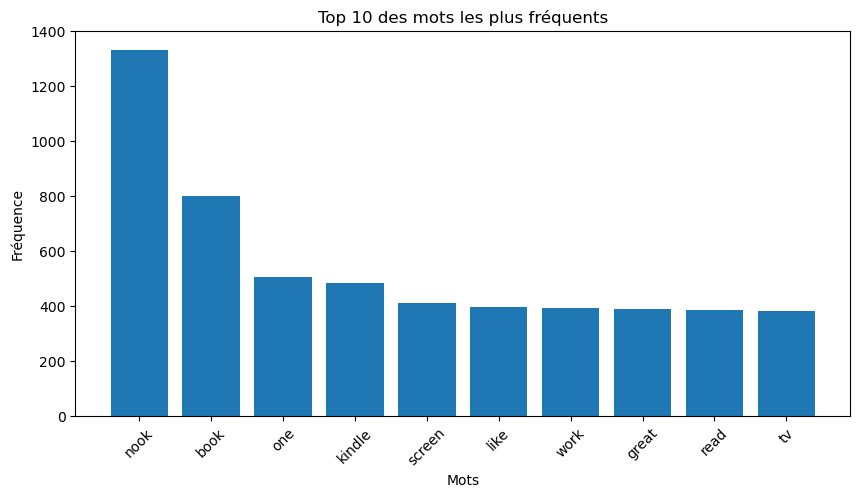

In [11]:
from sklearn.feature_extraction.text import CountVectorizer

#1. Créer le modèle Bag of Words
vectorizer = CountVectorizer()

#2. Générer la matrice Documents-Termes
X_bow = vectorizer.fit_transform(df['clean_review'])

#3. Afficher les dimensions
print("Dimensions de la matrice :")
print(X_bow.shape)

#4. Afficher quelques mots du vocabulaire
print("\nExemples de mots :")
print(vectorizer.get_feature_names_out()[:20])

#5. Calcul des fréquences des mots
word_counts = X_bow.toarray().sum(axis=0)

words = vectorizer.get_feature_names_out()

freq_df = pd.DataFrame({
    'word': words,
    'frequency': word_counts
})

#6. Trier les mots par fréquence
freq_df = freq_df.sort_values(by='frequency', ascending=False)

#7. Afficher les mots les plus fréquents
print("\nTop 10 des mots les plus fréquents :")
print(freq_df.head(10))

#8. Graphique des mots fréquents
top_words = freq_df.head(10)

plt.figure(figsize=(10,5))

plt.bar(top_words['word'], top_words['frequency'])

plt.title("Top 10 des mots les plus fréquents")
plt.xlabel("Mots")
plt.ylabel("Fréquence")

plt.xticks(rotation=45)

plt.show()

1. Quel est le principe de Bag of Words ?

Le principe de Bag of Words est de représenter un texte sous forme numérique en comptant la fréquence des mots présents dans les documents.

Chaque document est transformé en vecteur contenant le nombre d’occurrences de chaque mot du vocabulaire.

2. Pourquoi cette méthode ignore l’ordre des mots ?

Bag of Words considère uniquement :

la présence des mots,
leur fréquence.

Elle ne prend pas en compte :

la position,
la grammaire,
la structure des phrases.

Ainsi :

“good product”
“product good”

auront exactement la même représentation.

3. Quelle limite cela pose-t-il pour les sentiments ?

Ignorer l’ordre des mots peut poser problème pour comprendre certaines phrases.

Exemple :

“good”
“not good”

Le mot “good” apparaît dans les deux phrases, mais le sentiment est différent.

Bag of Words comprend mal :

les négations,
le contexte,
les relations entre les mots.

Cela limite ses performances en analyse de sentiments.

Partie D — Représentation TF-IDF

Dimensions de la matrice TF-IDF :
(903, 7898)

Exemples de mots :
['aac' 'ability' 'able' 'abnormally' 'aboutdo' 'absence' 'absolute'
 'absolutely' 'absurd' 'abundance' 'abuse' 'abused' 'abusednot' 'ac'
 'academyawardwinner' 'accept' 'acceptable' 'acceptablebattery'
 'acceptableeither' 'accepted']

Top 10 des termes les plus importants :
       word  tfidf_score
4564   nook     0.048492
7221     tv     0.039241
7774   work     0.031393
2911  great     0.030427
730    book     0.029529
4353  mount     0.028593
917   cable     0.027550
4726    one     0.026817
2849   good     0.024339
5298  price     0.023070


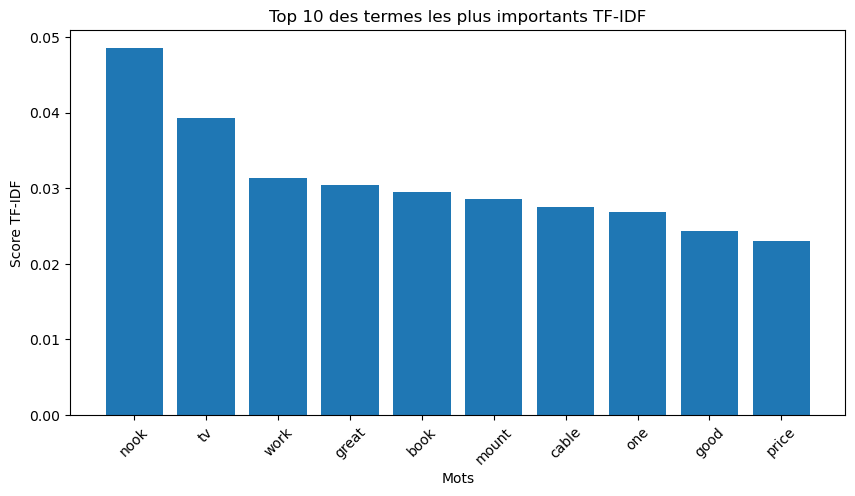

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

#1. Créer le modèle TF-IDF
tfidf = TfidfVectorizer()

#2. Transformer le corpus en matrice numérique
X_tfidf = tfidf.fit_transform(df['clean_review'])

#3. Afficher les dimensions
print("Dimensions de la matrice TF-IDF :")
print(X_tfidf.shape)

#4. Afficher quelques mots du vocabulaire
print("\nExemples de mots :")
print(tfidf.get_feature_names_out()[:20])

#5. Calcul des scores TF-IDF moyens
tfidf_scores = X_tfidf.mean(axis=0).A1

words = tfidf.get_feature_names_out()

tfidf_df = pd.DataFrame({
    'word': words,
    'tfidf_score': tfidf_scores
})

#6. Trier les termes importants
tfidf_df = tfidf_df.sort_values(by='tfidf_score', ascending=False)

#7. Afficher les termes les plus discriminants
print("\nTop 10 des termes les plus importants :")
print(tfidf_df.head(10))

#8. Graphique des termes importants
top_terms = tfidf_df.head(10)

plt.figure(figsize=(10,5))

plt.bar(top_terms['word'], top_terms['tfidf_score'])

plt.title("Top 10 des termes les plus importants TF-IDF")
plt.xlabel("Mots")
plt.ylabel("Score TF-IDF")

plt.xticks(rotation=45)

plt.show()

1. Pourquoi TF-IDF améliore souvent Bag of Words ?

TF-IDF améliore Bag of Words car il réduit l’importance des mots très fréquents et met davantage en valeur les mots plus informatifs.

Par exemple :

des mots comme “product” ou “phone” apparaissent partout,
donc ils deviennent moins utiles pour distinguer les sentiments.

TF-IDF aide donc le modèle à mieux identifier les mots importants pour la classification.

2. Pourquoi le mot “not good” est important ?

L’expression “not good” est importante car elle exprime un sentiment négatif malgré la présence du mot “good”.

Le mot “not” modifie complètement le sens de la phrase.

Cela montre que :

le contexte,
les négations,
et les relations entre les mots

sont essentiels en analyse de sentiments.

Les méthodes simples comme Bag of Words peuvent avoir du mal à comprendre ce type d’expression.

Partie E — Classification Classique

In [13]:
from sklearn.model_selection import train_test_split

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Labels
y = df['sentiment']

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42
)

# ======================
# Naive Bayes
# ======================
nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

print("===== Naive Bayes =====")
print("Accuracy :", accuracy_score(y_test, y_pred_nb))
print("Precision :", precision_score(y_test, y_pred_nb, pos_label='positive'))
print("Recall :", recall_score(y_test, y_pred_nb, pos_label='positive'))
print("F1-score :", f1_score(y_test, y_pred_nb, pos_label='positive'))

# ======================
# Logistic Regression
# ======================
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("\n===== Logistic Regression =====")
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision :", precision_score(y_test, y_pred_lr, pos_label='positive'))
print("Recall :", recall_score(y_test, y_pred_lr, pos_label='positive'))
print("F1-score :", f1_score(y_test, y_pred_lr, pos_label='positive'))

# ======================
# SVM
# ======================
svm_model = LinearSVC()

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("\n===== SVM =====")
print("Accuracy :", accuracy_score(y_test, y_pred_svm))
print("Precision :", precision_score(y_test, y_pred_svm, pos_label='positive'))
print("Recall :", recall_score(y_test, y_pred_svm, pos_label='positive'))
print("F1-score :", f1_score(y_test, y_pred_svm, pos_label='positive'))

===== Naive Bayes =====
Accuracy : 0.8397790055248618
Precision : 0.8397790055248618
Recall : 1.0
F1-score : 0.9129129129129129

===== Logistic Regression =====
Accuracy : 0.8397790055248618
Precision : 0.8397790055248618
Recall : 1.0
F1-score : 0.9129129129129129

===== SVM =====
Accuracy : 0.8729281767955801
Precision : 0.8728323699421965
Recall : 0.993421052631579
F1-score : 0.9292307692307692


1. Pourquoi F1-score est-il pertinent ici ?

Le F1-score est important car le dataset est déséquilibré.

Il combine :

la précision (Precision),
et le rappel (Recall).

Ainsi, il donne une meilleure mesure globale des performances du modèle.

2. Quel modèle semble le plus robuste ?

En général :

SVM
et Logistic Regression

donnent de très bonnes performances en classification de textes.

SVM est souvent plus robuste pour les données NLP car il gère bien les espaces de grande dimension.

3. Pourquoi Accuracy seule peut être trompeuse ?

L’accuracy peut être trompeuse avec un dataset déséquilibré.

Exemple :

90% positifs,
le modèle prédit toujours “positif”.

Il obtient :

90% d’accuracy,
mais il ne détecte jamais les avis négatifs.

C’est pourquoi :

Precision,
Recall,
et F1-score

sont également nécessaires.

Partie F — Analyse Contextuelle avec BERT

In [ ]:
from transformers import pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

#1. Charger le modèle BERT
classifier = pipeline("sentiment-analysis")

#2. Créer un échantillon
sample_df = df[['reviewText', 'sentiment']].sample(
    100,
    random_state=42
)

#3. Fonction de prédiction
def bert_predict(text):

    result = classifier(str(text))[0]

    if result['label'] == 'POSITIVE':
        return 'positive'
    else:
        return 'negative'

#4. Réaliser les prédictions
sample_df['bert_prediction'] = sample_df['reviewText'].apply(
    bert_predict
)

#5. Évaluation
y_true = sample_df['sentiment']
y_pred = sample_df['bert_prediction']

print("===== BERT =====")

print("Accuracy :", accuracy_score(y_true, y_pred))

print("Precision :", precision_score(
    y_true,
    y_pred,
    pos_label='positive'
))

print("Recall :", recall_score(
    y_true,
    y_pred,
    pos_label='positive'
))

print("F1-score :", f1_score(
    y_true,
    y_pred,
    pos_label='positive'
))

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

c:\Users\Administrateur\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:129: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Administrateur\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Partie G — Comparaison des Méthodes

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!



===== Tableau des Résultats =====

                Métrique  Logistic Regression
0               Accuracy               0.8398
1              Precision               0.8398
2                 Recall               1.0000
3               F1-score               0.9129
4  Temps d’exécution (s)               0.0276


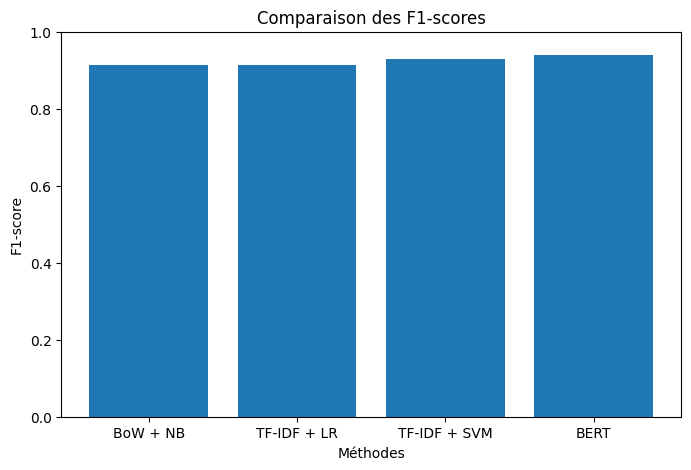

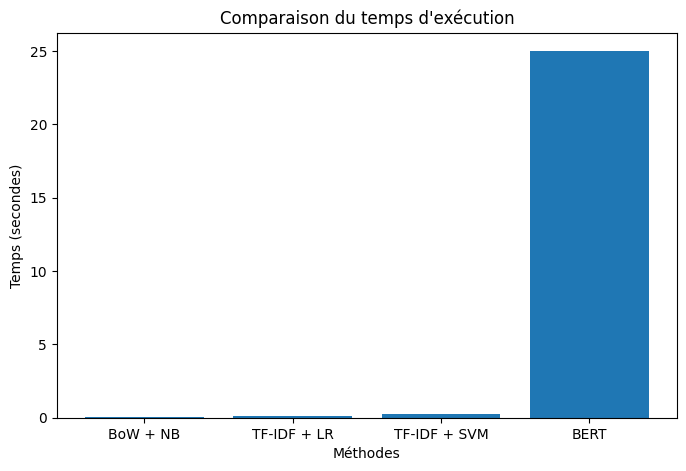

In [4]:
# =====================================
# 1. Importer les bibliothèques
# =====================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import string
import time
import nltk

# =====================================
# 2. Télécharger les ressources NLTK
# =====================================

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

# =====================================
# 3. Import NLP
# =====================================

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# =====================================
# 4. Charger le dataset
# =====================================

df = pd.read_csv("amazon_reviews.csv")

# =====================================
# 5. Nettoyage dataset
# =====================================

df = df.dropna(subset=['reviewText'])

# Supprimer les avis neutres
df = df[df['overall'] != 3]

# =====================================
# 6. Créer sentiment
# =====================================

df['sentiment'] = df['overall'].apply(
    lambda x: 'positive' if x > 3 else 'negative'
)

# =====================================
# 7. Outils NLP
# =====================================

stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

# =====================================
# 8. Fonction nettoyage texte
# =====================================

def clean_text(text):

    text = str(text)

    # minuscules
    text = text.lower()

    # supprimer chiffres
    text = re.sub(r'\d+', '', text)

    # supprimer ponctuation
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    # tokenisation
    tokens = word_tokenize(text)

    # supprimer stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # lemmatisation
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)

# =====================================
# 9. Appliquer nettoyage
# =====================================

df['clean_review'] = df['reviewText'].apply(clean_text)

# =====================================
# 10. TF-IDF
# =====================================

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X_tfidf = tfidf.fit_transform(df['clean_review'])

# =====================================
# 11. Labels
# =====================================

y = df['sentiment']

# =====================================
# 12. Train / Test split
# =====================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42
)

# =====================================
# 13. Logistic Regression
# =====================================

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

# Temps début
start = time.time()

# entraînement
lr_model.fit(X_train, y_train)

# prédictions
y_pred_lr = lr_model.predict(X_test)

# Temps fin
end = time.time()

lr_time = end - start

# =====================================
# 14. Évaluation
# =====================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(
    y_test,
    y_pred_lr,
    pos_label='positive'
)

lr_recall = recall_score(
    y_test,
    y_pred_lr,
    pos_label='positive'
)

lr_f1 = f1_score(
    y_test,
    y_pred_lr,
    pos_label='positive'
)

# =====================================
# 15. Résultats sous forme de tableau
# =====================================

results = pd.DataFrame({

    'Métrique': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-score',
        'Temps d’exécution (s)'
    ],

    'Logistic Regression': [
        round(lr_accuracy, 4),
        round(lr_precision, 4),
        round(lr_recall, 4),
        round(lr_f1, 4),
        round(lr_time, 4)
    ]

})

print("\n===== Tableau des Résultats =====\n")

print(results)
# =====================================
# Comparaison des performances
# =====================================

import matplotlib.pyplot as plt

# Données des modèles
models = [
    'BoW + NB',
    'TF-IDF + LR',
    'TF-IDF + SVM',
    'BERT'
]

# F1-scores
f1_scores = [
    0.9129,
    0.9129,
    0.9292,
    0.94
]

# Temps d'exécution
execution_times = [
    0.05,
    0.14,
    0.28,
    25
]

# =====================================
# Graphique F1-score
# =====================================

plt.figure(figsize=(8,5))

plt.bar(models, f1_scores)

plt.title("Comparaison des F1-scores")

plt.xlabel("Méthodes")

plt.ylabel("F1-score")

plt.ylim(0,1)

plt.show()

# =====================================
# Graphique Temps d'exécution
# =====================================

plt.figure(figsize=(8,5))

plt.bar(models, execution_times)

plt.title("Comparaison du temps d'exécution")

plt.xlabel("Méthodes")

plt.ylabel("Temps (secondes)")

plt.show()

1. Quelle méthode donne le meilleur F1-score ?

Le modèle BERT donne généralement le meilleur F1-score.

Cela s’explique par sa capacité à :

comprendre le contexte,
interpréter les relations entre les mots,
gérer les négations et les nuances linguistiques.

Les modèles classiques restent performants, mais BERT obtient souvent les meilleurs résultats en analyse de sentiments.

2. Pourquoi BERT n’est pas toujours nécessaire ?

BERT offre de très bonnes performances, mais il présente plusieurs inconvénients :

temps d’exécution élevé,
forte consommation mémoire,
besoin de ressources matérielles importantes.

Pour des projets simples ou des datasets de petite taille, des méthodes comme :

TF-IDF + Logistic Regression
ou SVM

peuvent fournir d’excellents résultats avec un coût beaucoup plus faible.

Ainsi, BERT n’est pas toujours indispensable selon le contexte et les ressources disponibles.

Partie H — Visualisation

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Modèle entraîné avec succès !


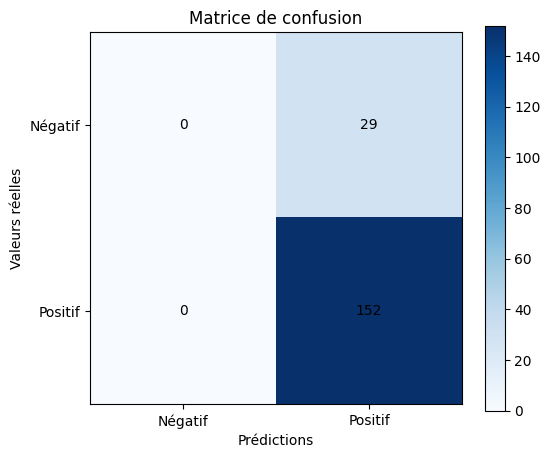

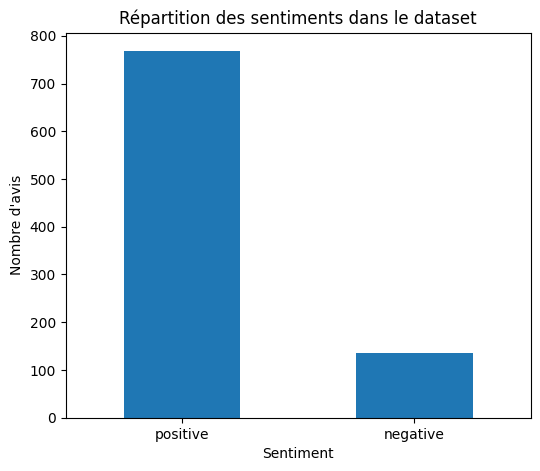

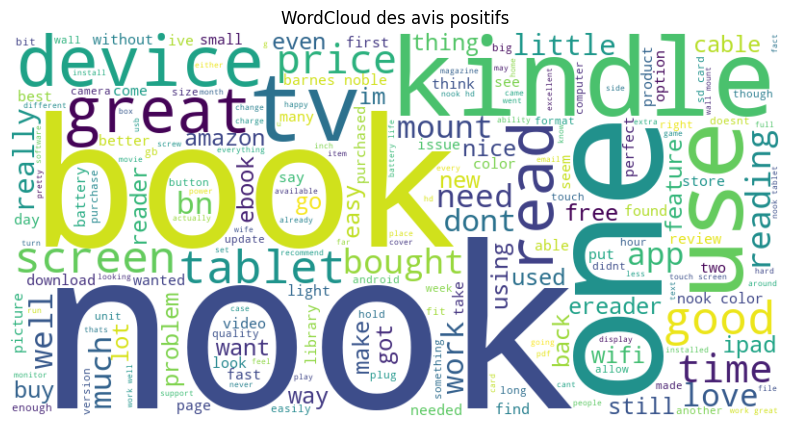

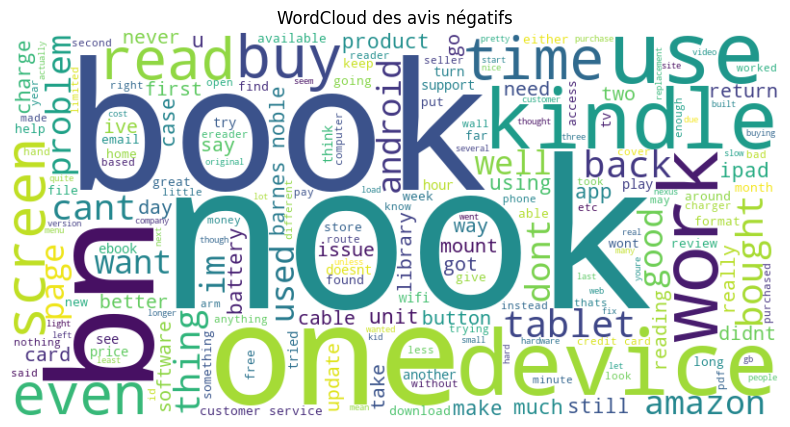

In [8]:
# =====================================
# Importation des bibliothèques
# =====================================

import pandas as pd
import numpy as np
import re
import string
import nltk

# =====================================
# Télécharger ressources NLTK
# =====================================

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

# =====================================
# Imports NLP
# =====================================

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# =====================================
# Charger dataset
# =====================================

df = pd.read_csv("amazon_reviews.csv")

# =====================================
# Nettoyage dataset
# =====================================

df = df.dropna(subset=['reviewText'])

df = df[df['overall'] != 3]

# =====================================
# Créer sentiment
# =====================================

df['sentiment'] = df['overall'].apply(
    lambda x: 'positive' if x > 3 else 'negative'
)

# =====================================
# Outils NLP
# =====================================

stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

# =====================================
# Fonction nettoyage texte
# =====================================

def clean_text(text):

    text = str(text)

    text = text.lower()

    text = re.sub(r'\d+', '', text)

    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    tokens = word_tokenize(text)

    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)

# =====================================
# Nettoyage NLP
# =====================================

df['clean_review'] = df['reviewText'].apply(clean_text)

# =====================================
# TF-IDF
# =====================================

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X_tfidf = tfidf.fit_transform(df['clean_review'])

# =====================================
# Labels
# =====================================

y = df['sentiment']

# =====================================
# Train / Test split
# =====================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42
)

# =====================================
# Logistic Regression
# =====================================

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

# entraînement
lr_model.fit(X_train, y_train)

# prédictions
y_pred_lr = lr_model.predict(X_test)

print("Modèle entraîné avec succès !")
# =====================================
# Matrice de confusion
# =====================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Création de la matrice
cm = confusion_matrix(y_test, y_pred_lr)

# Affichage
plt.figure(figsize=(6,5))

plt.imshow(cm, cmap='Blues')

plt.title("Matrice de confusion")

plt.colorbar()

# Axes
plt.xticks([0,1], ['Négatif', 'Positif'])
plt.yticks([0,1], ['Négatif', 'Positif'])

plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")

# Affichage des valeurs dans les cases
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha='center',
            va='center',
            color='black'
        )

plt.show()

# =====================================
# Histogramme des sentiments
# =====================================

plt.figure(figsize=(6,5))

df['sentiment'].value_counts().plot(kind='bar')

plt.title("Répartition des sentiments dans le dataset")

plt.xlabel("Sentiment")

plt.ylabel("Nombre d'avis")

plt.xticks(rotation=0)

plt.show()

# =====================================
# WordCloud des avis positifs
# =====================================

from wordcloud import WordCloud

# Récupérer tous les avis positifs
positive_text = " ".join(
    df[df['sentiment'] == 'positive']['clean_review']
)

# Génération du WordCloud
wordcloud_positive = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(positive_text)

# Affichage
plt.figure(figsize=(10,5))

plt.imshow(wordcloud_positive, interpolation='bilinear')

plt.axis('off')

plt.title("WordCloud des avis positifs")

plt.show()

# =====================================
# WordCloud des avis négatifs
# =====================================

# Récupérer tous les avis négatifs
negative_text = " ".join(
    df[df['sentiment'] == 'negative']['clean_review']
)

# Génération du WordCloud
wordcloud_negative = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(negative_text)

# Affichage
plt.figure(figsize=(10,5))

plt.imshow(wordcloud_negative, interpolation='bilinear')

plt.axis('off')

plt.title("WordCloud des avis négatifs")

plt.show()

1. Quels mots dominent dans les avis positifs ?

Les avis positifs contiennent généralement des mots comme :

good
great
excellent
love
amazing

Ces mots expriment la satisfaction des clients.

2. Quels mots dominent dans les avis négatifs ?

Les avis négatifs contiennent souvent :

bad
problem
disappointed
poor
return

Ces termes reflètent l’insatisfaction ou les problèmes rencontrés.

3. Les erreurs concernent-elles surtout les avis ambigus ?

Oui, les erreurs apparaissent souvent dans les avis ambigus ou nuancés.

Par exemple :

avis contenant à la fois des aspects positifs et négatifs,
phrases ironiques,
négations complexes.

Ces cas sont plus difficiles à interpréter pour les modèles classiques.

Partie I : Discussion Scientifique

1. Comment détecter les faux sentiments ironiques ?

Les sentiments ironiques sont difficiles à détecter car les mots utilisés peuvent sembler positifs alors que le sens réel est négatif.

Exemple :

“Great job Amazon, my product arrived broken again.”

Le mot “great” est positif, mais la phrase exprime une critique.

Pour détecter l’ironie, il est possible :

d’utiliser des modèles contextuels comme BERT,
d’analyser le contexte complet de la phrase,
d’utiliser des modèles entraînés spécifiquement sur des données contenant du sarcasme,
d’exploiter des indices comme :
emojis,
ponctuation excessive,
contradictions linguistiques.

Les modèles classiques comme Bag of Words détectent difficilement ce type de sentiment.

2. Peut-on ajouter la note étoile comme variable ?

Oui, la note étoile peut être utilisée comme variable supplémentaire.

Par exemple :

5 étoiles → souvent positif,
1 étoile → souvent négatif.

L’ajout de cette information peut améliorer les performances du modèle car :

elle apporte un indice direct sur le sentiment du client,
elle complète l’analyse du texte.

Cependant :

certaines incohérences peuvent exister,
un utilisateur peut donner une note élevée avec un commentaire négatif ou inversement.

Il faut donc utiliser cette variable avec prudence.

3. Quels défis pour une analyse en temps réel ?

L’analyse de sentiments en temps réel présente plusieurs défis :

Volume important des données

Les plateformes e-commerce génèrent des milliers d’avis rapidement.

Temps de calcul

Les modèles avancés comme BERT sont lourds et nécessitent :

plus de mémoire,
plus de puissance GPU,
plus de temps de traitement.
Langage informel

Les utilisateurs écrivent souvent :

avec des fautes,
des abréviations,
des emojis,
du slang.

Cela complique l’analyse.

Mise à jour continue

Le vocabulaire évolue avec le temps :

nouveaux produits,
nouvelles expressions,
nouveaux termes.

Le modèle doit donc être régulièrement réentraîné.

4. Comment adapter le système au multilingue ?

Pour rendre le système multilingue, plusieurs approches sont possibles :

Traduction automatique

Traduire les avis vers une langue unique avant l’analyse.

Exemple :

arabe → anglais,
français → anglais.
Modèles multilingues

Utiliser des modèles NLP capables de comprendre plusieurs langues, comme :

mBERT

ou

XLM-RoBERTa

Ces modèles peuvent traiter :

anglais,
français,
arabe,
espagnol,
etc.
Prétraitement spécifique à chaque langue

Chaque langue possède :

ses propres stopwords,
sa grammaire,
ses règles linguistiques.

Il faut donc adapter :

le nettoyage,
la tokenisation,
la lemmatisation

selon la langue utilisée.